# PyTorch로 GAN 구현하기 — MNIST 손글씨 이미지 생성

PyTorch를 이용하여 \*\*GAN(Generative Adversarial Network)\*\*을 처음부터 구현한다. MNIST 손글씨 데이터를 학습한 뒤, Generator가 새로운 숫자 이미지를 생성하는 실습이다.

이번 예제는 GAN의 원리를 이해하기 쉽도록 Fully Connected Layer(완전연결층) 기반의 기본 GAN을 사용한다.

## 1. GAN 전체 구조
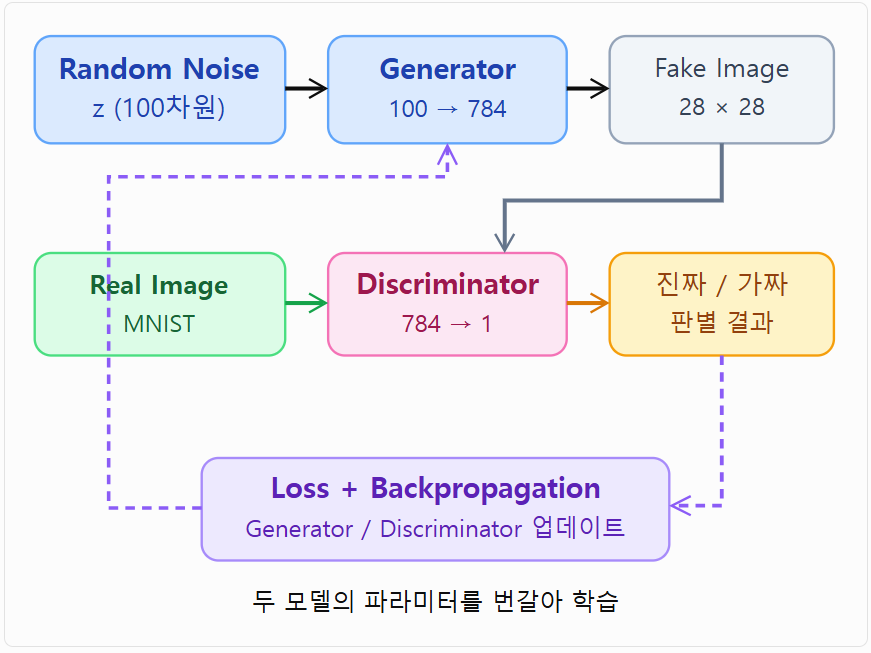

## 2. 라이브러리 설치

```
uv add torch torchvision matplotlib
```

## 3. 학습 결과 이해

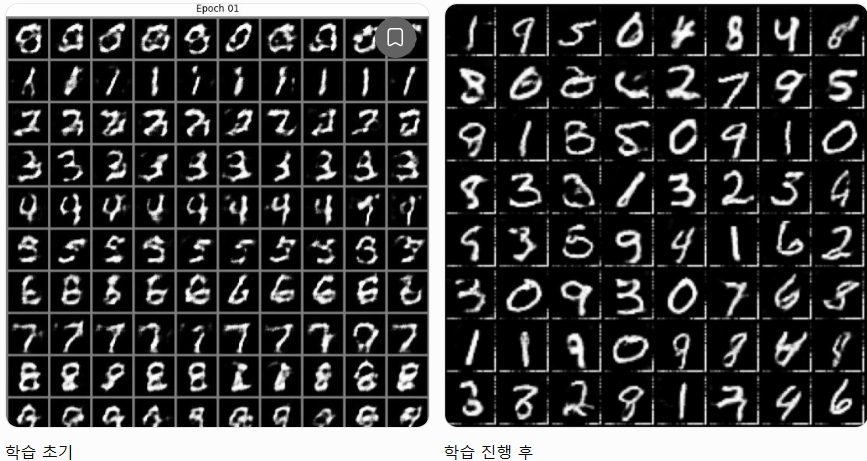

숫자의 획과 형태가 점차 뚜렷해질 수 있다.

위 이미지는 학습 단계의 예시이며, 제공한 코드를 실행하여 얻은 실제 결과는 아니다. 실제 출력은 난수, 학습 환경, 학습 안정성에 따라 달라진다.

## 4. 핵심 코드 설명

| 코드                        | 역할                             |
| ------------------------- | ------------------------------ |
| `torch.randn()`           | Generator 입력 노이즈 생성            |
| `G(z)`                    | 노이즈를 가짜 이미지로 변환                |
| `D(real_images)`          | 실제 이미지 판별                      |
| `D(fake_images.detach())` | Generator의 기울기 계산 없이 가짜 이미지 판별 |
| `d_loss.backward()`       | Discriminator의 기울기 계산          |
| `optimizer_D.step()`      | Discriminator 가중치 갱신           |
| `g_loss.backward()`       | Generator로 기울기 역전파             |
| `optimizer_G.step()`      | Generator 가중치 갱신               |

특히 `detach()`는 중요한 개념이다. Discriminator를 학습하는 단계에서는 Generator의 가중치가 변경되지 않도록 생성 이미지와 Generator의 계산 그래프를 분리한다.

반대로 Generator 학습 단계에서는 `detach()`를 사용하지 않는다. Discriminator의 연산을 통과한 손실의 기울기가 Generator까지 전달되어야 하기 때문이다.

또한 `optimizer_G.step()`은 Generator의 파라미터만 변경한다. 이 예제에서는 Generator 학습 단계에서 Discriminator의 기울기도 계산될 수 있지만, Discriminator의 파라미터는 해당 단계에서 업데이트되지 않는다.



Device: cpu
z.shape tensor([[ 1.2807,  1.6511,  0.0549,  ...,  0.3106,  1.8526, -0.4750],
        [-0.1625,  0.9754,  2.0699,  ...,  1.1406,  0.6719,  0.5597],
        [-0.1925, -0.6599,  0.6920,  ...,  1.0151,  0.1923, -0.1213],
        ...,
        [ 1.7024,  0.6447,  0.9428,  ...,  0.0830,  0.4303,  0.3139],
        [ 0.2443, -0.3234, -0.0589,  ..., -1.5653,  0.9048, -0.3831],
        [-0.0252,  0.9601,  2.4071,  ..., -0.5225, -1.3437, -0.7335]])
z.shape tensor([[-0.3195,  0.4421, -0.9413,  ..., -0.5600,  0.3273,  0.6194],
        [-0.2188, -1.3525, -0.8099,  ..., -0.4730, -1.0870, -0.4809],
        [ 1.3595,  0.7290, -0.6427,  ...,  0.3112,  0.3960, -0.6413],
        ...,
        [-0.3862, -0.3607,  1.4715,  ...,  1.0093, -1.1247,  0.1197],
        [-0.9975, -1.4142,  1.1769,  ..., -0.3818,  0.3975, -1.6312],
        [ 0.6893,  1.0241,  0.1805,  ...,  1.7998,  1.5454,  0.1148]])
z.shape tensor([[-0.8896,  0.6789, -0.8935,  ..., -1.1784,  0.1356, -0.8574],
        [-0.8008,  0.0752,

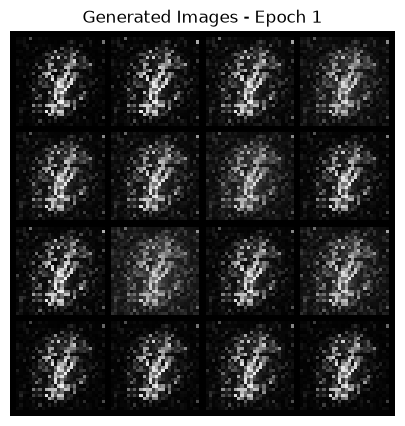

z.shape tensor([[-0.0535,  1.6973, -0.9686,  ...,  1.1144, -0.4875, -0.6791],
        [ 0.5651,  1.3443,  1.0842,  ...,  0.1869,  1.3135, -0.8425],
        [ 1.1784, -1.1082, -0.2350,  ..., -0.5542,  0.5169, -0.1021],
        ...,
        [ 0.7336,  1.3375, -1.2230,  ..., -0.7167, -1.0331,  1.8478],
        [ 0.7004, -1.8460,  0.5881,  ..., -0.0941,  1.3790, -0.8409],
        [-1.4361,  0.1218, -0.5244,  ..., -0.8557, -0.0304, -0.5888]])
z.shape tensor([[-0.5006,  0.1208,  0.5820,  ..., -0.7818, -1.3560, -0.2028],
        [-0.4717, -0.2019,  0.1880,  ..., -1.1469,  1.3767, -0.6189],
        [ 1.5217,  0.2422,  0.5765,  ...,  0.5272,  2.1704, -0.6711],
        ...,
        [ 0.8936, -1.5486,  0.7427,  ...,  0.7598,  0.5238,  1.4492],
        [-0.4757,  0.2788, -0.1007,  ...,  0.2289, -1.0850, -0.0912],
        [ 0.7406, -0.2479,  1.7188,  ...,  0.7640, -0.9392, -0.6414]])
z.shape tensor([[ 0.5933, -0.7591,  0.9896,  ...,  0.5745,  1.1578,  0.8534],
        [ 0.1611,  0.1160, -1.8286,  .

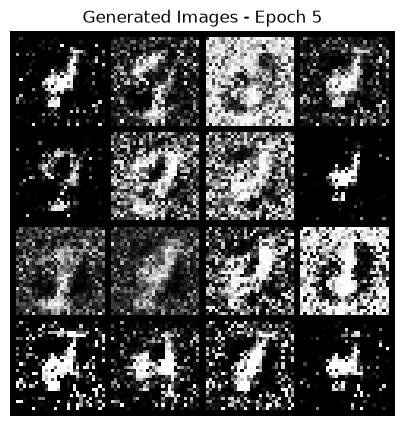

z.shape tensor([[ 0.1310, -0.5438, -0.3007,  ..., -1.2438,  0.5073,  2.2114],
        [-0.7447, -0.7625,  0.4624,  ..., -0.3305,  0.3801,  1.0035],
        [-0.0595, -1.6886, -2.5981,  ...,  0.3685,  0.3490,  0.1407],
        ...,
        [ 1.8784, -0.7646, -0.0464,  ...,  0.7718,  0.1248,  0.4194],
        [ 1.9490, -0.8426, -1.0900,  ...,  0.3381, -1.5814,  0.2251],
        [-0.3405,  0.1387, -2.0312,  ...,  1.0596,  0.6525, -2.2239]])
z.shape tensor([[-1.1240, -0.6521, -0.8882,  ...,  0.7061,  0.7050,  0.7354],
        [-0.2135,  1.0892,  0.2223,  ..., -1.1661,  0.5292, -1.6289],
        [-0.2773,  0.2106,  1.2349,  ...,  0.7041,  0.5939,  1.4714],
        ...,
        [-0.3189, -0.9364,  1.2984,  ...,  0.5290,  1.0187, -0.2525],
        [-0.3780, -0.5804, -1.3115,  ..., -1.9307,  0.5409,  1.2845],
        [-0.5242,  0.3416,  0.6211,  ...,  0.5941,  0.9770,  0.1726]])
z.shape tensor([[-0.6181, -1.1842, -0.4859,  ..., -0.2614,  0.1587,  1.1265],
        [-0.2104,  1.3293,  0.3843,  .

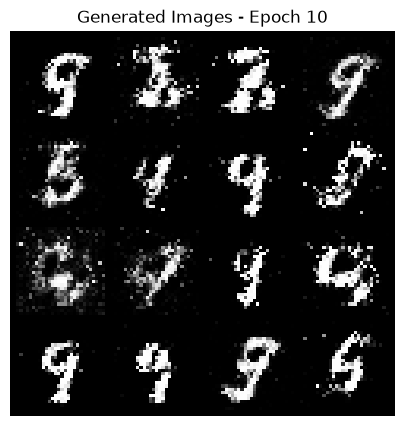

z.shape tensor([[ 0.2386, -1.0371,  0.7089,  ..., -1.0440,  1.5095,  0.1820],
        [-1.0345, -0.0070,  0.9106,  ..., -0.4674,  0.7981, -0.1189],
        [ 0.8385,  0.5090,  2.3628,  ...,  1.2528, -0.8326, -0.9478],
        ...,
        [ 0.0965, -0.4192,  1.0163,  ..., -0.1148,  0.1794, -0.9277],
        [-0.5298, -1.5556, -0.4241,  ..., -1.1628, -0.2196, -0.7064],
        [-0.5120, -2.1090,  1.6490,  ..., -0.7903, -0.2881, -0.1446]])
z.shape tensor([[ 3.1194, -0.5148,  1.1704,  ..., -1.1505,  0.7917, -0.5271],
        [-0.3218, -0.0477, -0.1540,  ...,  1.7684,  0.2962,  1.5049],
        [-1.3550, -0.2924, -1.4172,  ..., -1.9530,  0.9958, -0.0962],
        ...,
        [-0.5632,  0.1909,  1.0400,  ...,  0.5462,  0.9459, -0.3745],
        [-0.3002,  0.6310, -1.8652,  ...,  0.3758,  0.0251,  0.0561],
        [ 0.2916,  0.1391, -0.4273,  ..., -0.1253, -0.7039, -0.0268]])
z.shape tensor([[ 0.3790, -1.4890,  0.2320,  ...,  0.9049, -1.3059, -1.2643],
        [-0.5446,  1.8237,  0.2820,  .

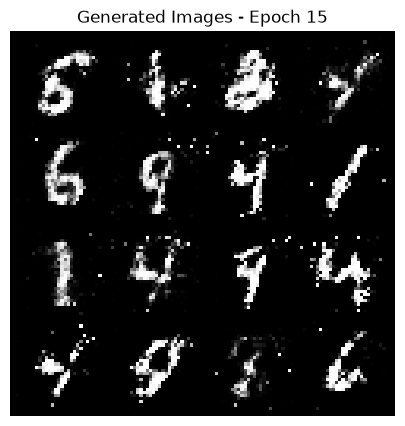

z.shape tensor([[-1.6835, -0.5781, -1.8254,  ...,  0.6243,  0.2262, -0.1666],
        [ 0.5668, -0.6027,  1.5921,  ..., -1.1343, -1.2751, -0.3501],
        [-1.9415, -0.6707, -0.1118,  ..., -1.5419,  0.3681, -2.2630],
        ...,
        [-0.2478,  0.6816, -0.1362,  ...,  0.1589,  0.5451, -0.4384],
        [ 0.2812, -0.3689, -0.6055,  ..., -0.7384,  0.4288,  0.2033],
        [ 0.2293, -0.7642,  1.3964,  ..., -1.9077, -0.7467,  0.2581]])
z.shape tensor([[ 8.4879e-01,  2.1297e-01,  5.1199e-02,  ..., -1.4508e-01,
          6.0232e-01,  1.4540e+00],
        [ 1.0843e+00,  3.3503e-01,  7.2789e-01,  ...,  1.7390e+00,
         -3.6143e-03,  1.0127e+00],
        [ 8.2542e-02, -1.2107e-03, -1.3666e-01,  ...,  1.0604e-01,
         -2.4338e+00, -3.1952e-02],
        ...,
        [ 7.3207e-01, -4.4067e-01, -6.7020e-01,  ...,  1.4263e+00,
          6.2208e-01, -1.2379e+00],
        [-1.9980e-01,  2.1530e-01,  4.5214e-01,  ...,  3.5591e-01,
         -1.5332e+00,  1.3650e+00],
        [ 8.8457e-01, 

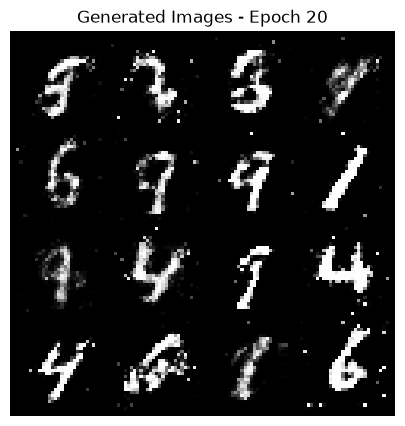

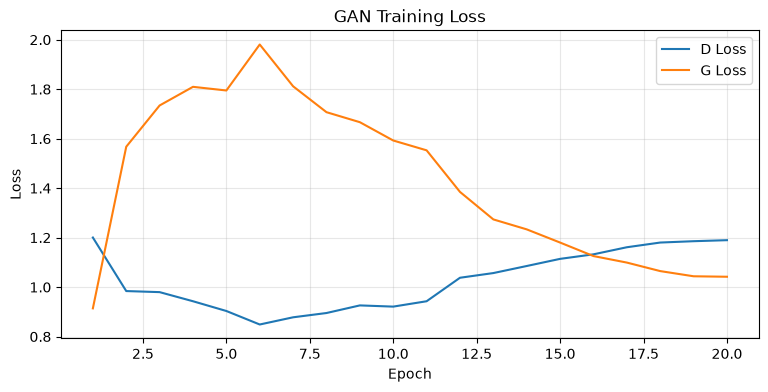

Generator 저장 완료: gan_generator.pth


In [1]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

# --------------------------------------------------
# 1. 기본 환경 설정
# --------------------------------------------------
# CUDA → MPS → CPU 순서로 사용 가능한 장치를 선택한다.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
# 재현성을 위한 난수 시드를 설정한다.
torch.manual_seed(42)
# GAN에 입력할 무작위 노이즈 벡터의 차원이다.
LATENT_DIM = 100
# MNIST 이미지 크기: 28 × 28 = 784
IMAGE_DIM = 28 * 28
# 한 번에 학습할 이미지 개수이다.
BATCH_SIZE = 128
# 전체 학습 데이터를 반복하는 횟수이다.
EPOCHS = 20
# Adam 옵티마이저의 학습률이다.
LR = 0.0002
print("Device:", device)

# --------------------------------------------------
# 2. MNIST 데이터셋 준비
# --------------------------------------------------
# transforms.Compose():여러 이미지 전처리 작업을 순서대로 실행하도록 묶는 함수
# 이미지를 Tensor로 변환한다.
# 원본 픽셀 [0, 1]을 [-1, 1]로 정규화한다.
# Generator의 마지막 Tanh 출력 범위와 일치시킨다.
transform = transforms.Compose([
    transforms.ToTensor(),  # 1단계
    transforms.Normalize((0.5,), (0.5,))  #2단계
])
# MNIST 학습 데이터 60,000장을 다운로드한다.
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)
# 미니배치 단위로 데이터를 공급한다.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=0
)

# --------------------------------------------------
# 3. Generator 모델 정의
# --------------------------------------------------
# 무작위 노이즈 z를 받아 가짜 MNIST 이미지를 생성한다.
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # 100차원 노이즈를 256차원 특징으로 변환한다.
            nn.Linear(LATENT_DIM, 256),
            nn.LeakyReLU(0.2),
            # 특징을 512차원으로 확장한다.
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            # 512차원을 1024차원으로 확장한다.
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            # 최종적으로 784개의 픽셀값을 생성한다.
            nn.Linear(1024, IMAGE_DIM),
            # 출력 픽셀값을 [-1, 1] 범위로 제한한다.
            nn.Tanh()
        )

    def forward(self, z):
        # 입력 z의 형태: (batch_size, 100)
        # 출력의 형태: (batch_size, 784)
        return self.model(z)

# --------------------------------------------------
# 4. Discriminator 모델 정의
# --------------------------------------------------
# 이미지가 실제 데이터인지 생성 데이터인지 판별한다.
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            # 784개의 픽셀값을 입력받는다.
            nn.Linear(IMAGE_DIM, 512),
            nn.LeakyReLU(0.2),
            # 특징을 256차원으로 축소한다.
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            # 진짜/가짜 판별을 위한 점수 1개를 출력한다.
            nn.Linear(256, 1)
            # Sigmoid를 사용하지 않는다.
            # BCEWithLogitsLoss가 내부적으로 처리한다.
        )

    def forward(self, x):
        return self.model(x)

# --------------------------------------------------
# 5. 모델, 손실함수, 옵티마이저 생성
# --------------------------------------------------
# 두 모델을 선택한 장치로 이동한다.
G = Generator().to(device)
D = Discriminator().to(device)
# 이진 분류 손실함수를 사용한다.
criterion = nn.BCEWithLogitsLoss()
# Generator의 파라미터만 업데이트하는 옵티마이저이다.
optimizer_G = torch.optim.Adam(
    G.parameters(), lr=LR, betas=(0.5, 0.999)
)
# Discriminator의 파라미터만 업데이트하는 옵티마이저이다.
optimizer_D = torch.optim.Adam(
    D.parameters(), lr=LR, betas=(0.5, 0.999)
)
# 에폭별 평균 손실을 저장한다.
g_losses = []
d_losses = []
# 학습 경과를 비교하기 위해 고정된 노이즈를 사용한다.
fixed_noise = torch.randn(16, LATENT_DIM, device=device)

# --------------------------------------------------
# 6. 생성 이미지 출력 함수
# --------------------------------------------------
def show_generated_images(epoch):
    # 평가 모드로 전환한다.
    G.eval()
    # 시각화 과정에서는 기울기를 계산하지 않는다.
    with torch.no_grad():
        # 고정된 노이즈로 16장의 이미지를 생성한다.
        fake_images = G(fixed_noise)
        # 784차원 벡터를 1 × 28 × 28 이미지로 변환한다.
        fake_images = fake_images.reshape(-1, 1, 28, 28)
        # [-1, 1] 범위를 [0, 1]로 복원한다.
        fake_images = (fake_images + 1) / 2
        # 4 × 4 격자 형태로 이미지를 배치한다.
        grid = make_grid(fake_images.cpu(), nrow=4)
        # 이미지 시각화
        plt.figure(figsize=(5, 5))
        plt.imshow(grid.permute(1, 2, 0).numpy())
        plt.title(f"Generated Images - Epoch {epoch}")
        plt.axis("off")
        plt.show()
    # 다시 학습 모드로 전환한다.
    G.train()

# --------------------------------------------------
# 7. GAN 학습
# --------------------------------------------------
for epoch in range(EPOCHS):
    # 각 에폭의 손실 누적값이다.
    total_g_loss = 0.0
    total_d_loss = 0.0

    for real_images, _ in train_loader:
        # 실제 이미지 배치를 학습 장치로 이동한다.
        real_images = real_images.to(device)
        # 28 × 28 이미지를 784차원 벡터로 변환한다.
        real_images = real_images.reshape(-1, IMAGE_DIM)
        # 마지막 배치 크기가 128보다 작을 수 있다.
        batch_size = real_images.size(0)

        # ------------------------------------------
        # Step 1. Discriminator 학습
        # ------------------------------------------
        # 이전 배치에서 계산된 D의 기울기를 초기화한다.
        optimizer_D.zero_grad()

        # 실제 이미지는 정답 레이블 1을 사용한다.
        real_labels = torch.ones(batch_size, 1, device=device)
        # 생성 이미지는 정답 레이블 0을 사용한다.
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # 실제 이미지에 대한 판별 결과를 계산한다.
        real_outputs = D(real_images)
        # 실제 이미지를 진짜(1)로 판별하도록 손실을 계산한다.
        d_real_loss = criterion(real_outputs, real_labels)

        # 정규분포에서 무작위 노이즈를 생성한다. (128, 100)
        z = torch.randn(batch_size, LATENT_DIM, device=device)
        print('z.shape', z  )
        # Generator가 가짜 이미지를 생성한다.
        fake_images = G(z)
        # 생성 이미지에 대한 판별 결과를 계산한다.
        # detach()로 Generator까지 기울기가 전달되지 않게 한다.
        fake_outputs = D(fake_images.detach())
        # 가짜 이미지를 가짜(0)로 판별하도록 손실을 계산한다.
        d_fake_loss = criterion(fake_outputs, fake_labels)

        # 실제/가짜 이미지에 대한 손실을 합산한다.
        d_loss = d_real_loss + d_fake_loss
        # D의 파라미터에 대한 기울기를 계산한다.
        d_loss.backward()
        # Discriminator의 파라미터를 업데이트한다.
        optimizer_D.step()

        # ------------------------------------------
        # Step 2. Generator 학습
        # ------------------------------------------
        # 이전 배치에서 계산된 G의 기울기를 초기화한다.
        optimizer_G.zero_grad()
        # 새 노이즈로 가짜 이미지를 생성한다.
        z = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = G(z)
        # 생성 이미지에 대한 판별 점수를 얻는다.
        fake_outputs = D(fake_images)
        # Generator는 가짜 이미지가 진짜(1)로
        # 판별되도록 학습한다.
        g_loss = criterion(fake_outputs, real_labels)
        # Generator까지 기울기를 역전파한다.
        g_loss.backward()
        # Generator의 파라미터를 업데이트한다.
        optimizer_G.step()

        # 손실값을 누적한다.
        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    # 배치별 손실의 평균을 계산한다.
    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)
    # 에폭별 평균 손실을 저장한다.
    d_losses.append(avg_d_loss)
    g_losses.append(avg_g_loss)
    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f}"
    )
    # 1, 5, 10, 15, 20 에폭에서 생성 결과를 확인한다.
    if (epoch + 1) == 1 or (epoch + 1) % 5 == 0:
        show_generated_images(epoch + 1)

# --------------------------------------------------
# 8. 손실 그래프 시각화
# --------------------------------------------------
plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS + 1), d_losses, label="D Loss")
plt.plot(range(1, EPOCHS + 1), g_losses, label="G Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# --------------------------------------------------
# 9. 학습된 Generator 저장
# --------------------------------------------------
torch.save(G.state_dict(), "gan_generator.pth")
print("Generator 저장 완료: gan_generator.pth")


# GAN 학습 손실 그래프 분석

제공한 20 Epoch의 GAN 학습 그래프를 분석하면, 초반에는 Discriminator가 상대적으로 우세하지만, 후반에는 Generator와 Discriminator의 경쟁 관계가 변화하면서 손실이 안정화되는 양상을 보인다.

다만 손실 그래프만으로 Mode Collapse가 발생했다고 판단할 수는 없다.

## 1. Epoch 구간별 분석

| 구간     | D Loss         | G Loss         | 해석                         |
| ------ | -------------- | -------------- | -------------------------- |
| 1\~3   | 1.15 → 0.91 감소 | 0.97 → 1.91 증가 | 판별자의 구분 능력이 상대적으로 향상       |
| 4\~10  | 약 0.80\~0.94   | 약 1.74\~2.04   | 판별자가 상대적으로 우세한 구간          |
| 11\~15 | 0.87 → 1.10 증가 | 1.79 → 1.21 감소 | 생성자가 판별자를 속이기 쉬워지는 방향으로 변화 |
| 16\~20 | 약 1.13\~1.17   | 약 1.09\~1.17   | 손실 변화 폭이 줄어드는 양상           |

수치는 그래프를 육안으로 판독한 근삿값이다.

## 2. 학습 불안정성 분석

### ① 초기 학습 (Epoch 1\~10)

- D Loss가 감소하면서 G Loss는 증가한다.
- 판별자가 실제 이미지와 가짜 이미지를 상대적으로 잘 구분하는 방향으로 학습되고 있다고 해석할 수 있다.
- G Loss가 약 2.04까지 증가하지만, 이것만으로 학습 실패를 의미하지는 않는다.

### ② 중기 학습 (Epoch 11\~15)

- G Loss가 약 1.79에서 1.21로 감소한다.
- 반대로 D Loss는 약 0.87에서 1.10으로 증가한다.
- Generator가 판별자를 속이기 쉬워지고 있을 가능성이 있다.

다만 판별자의 성능 저하가 생성 이미지 품질 향상 때문인지, 생성 이미지의 다양성 감소 때문인지는 추가 확인이 필요하다.

### ③ 후기 학습 (Epoch 16\~20)

- 두 손실값이 약 1.1 부근으로 접근한다.
- 손실의 급격한 진동이나 발산은 관찰되지 않는다.
- 따라서 수치상으로는 학습이 비교적 안정적인 방향으로 진행되고 있다.

단, GAN에서 D Loss와 G Loss가 비슷해진다는 것이 반드시 학습 성공이나 수렴을 의미하지는 않는다.

## 3. Mode Collapse 발생 여부

Mode Collapse는 Generator가 다양한 이미지를 생성하지 못하고 특정 유형의 이미지만 반복적으로 생성하는 현상이다.

예를 들어 MNIST에서 Generator가 숫자 0, 1, 2, …, 9를 다양하게 생성해야 하는데 숫자 3과 8만 반복해서 생성한다면 Mode Collapse를 의심할 수 있다.

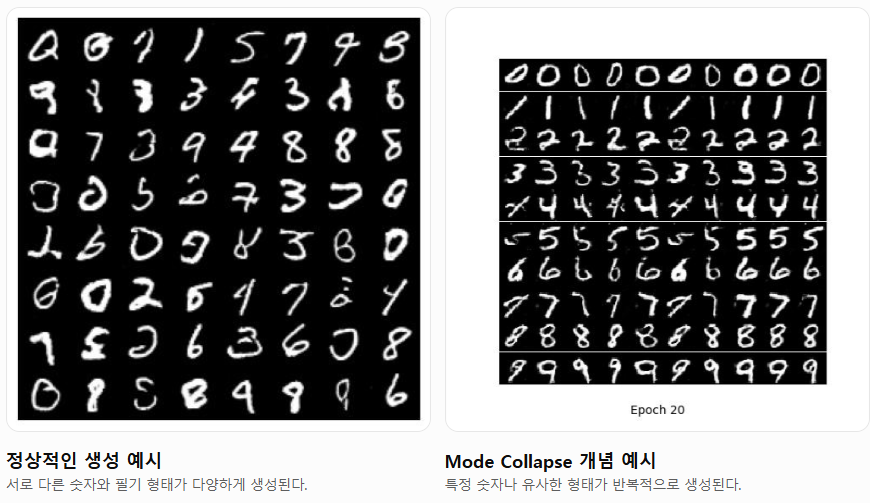


위 이미지는 개념 설명을 위한 참고 이미지이며, 실제 모델의 출력은 아니다.

### 현재 그래프에서 판단할 수 있는 내용

| 평가 항목           | 결과                          |
| --------------- | --------------------------- |
| 손실 발산           | 관찰되지 않음                     |
| 급격한 손실 진동       | 일부 변화는 있으나 지속적인 진동은 뚜렷하지 않음 |
| Generator 학습 진행 | 손실 변화가 나타나지만 품질 개선 여부는 미확인  |
| Mode Collapse   | 손실 그래프만으로 판정 불가             |
| 최종 학습 안정성       | 후반부 손실 변동이 감소하는 경향          |

## 4. Mode Collapse 확인을 위한 추가 코드

현재 학습한 `G` 모델을 이용하여 100장의 이미지를 생성하고, 숫자의 다양성을 직접 확인할 수 있다.


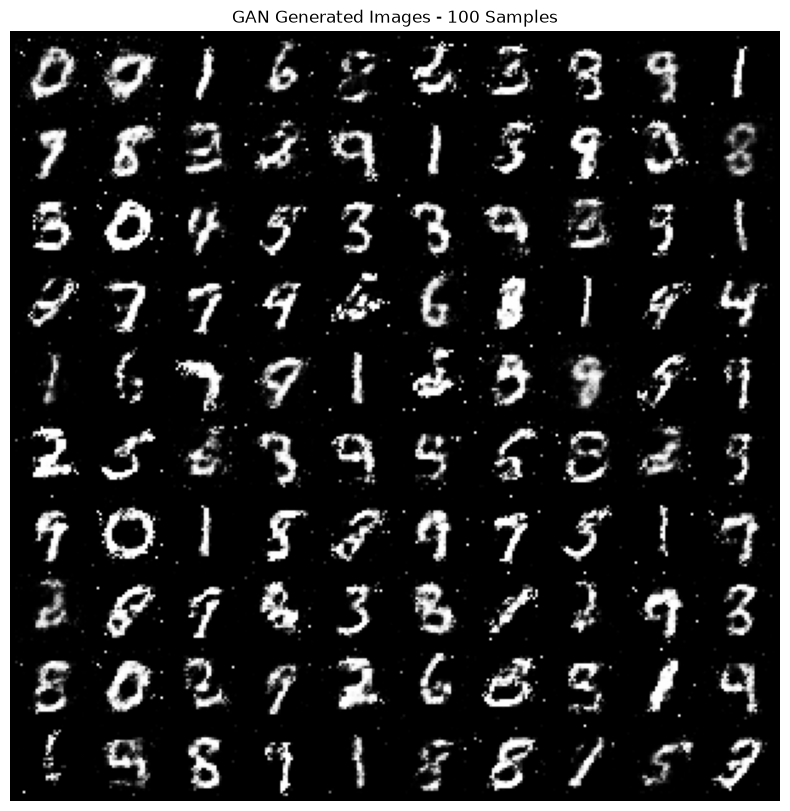

In [2]:
# Generator를 평가 모드로 변경한다.
G.eval()

# 생성 이미지 100장에 사용할 노이즈를 만든다.
z = torch.randn(100, LATENT_DIM, device=device)

# 기울기를 계산하지 않고 이미지를 생성한다.
with torch.inference_mode():
    fake_images = G(z)

    # 784차원 벡터를 28 × 28 이미지로 변환한다.
    fake_images = fake_images.reshape(-1, 1, 28, 28)

    # [-1, 1] 범위를 [0, 1]로 복원한다.
    fake_images = (fake_images + 1) / 2

# 100장을 10 × 10 격자로 배치한다.
grid = make_grid(
    fake_images.cpu(),
    nrow=10,
    padding=2
)

# 생성 이미지 출력
plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("GAN Generated Images - 100 Samples")
plt.axis("off")
plt.show()


# GAN 생성 이미지 100장 분석 결과

제공한 이미지는 MNIST 데이터셋으로 20 Epoch 학습한 GAN이 생성한 100장의 숫자 이미지이다.

분석 결과, 심각한 Mode Collapse는 관찰되지 않으며, GAN이 다양한 숫자 형태를 학습한 것으로 판단된다. 다만 일부 숫자의 형태가 불명확하고 배경 노이즈가 존재하므로 생성 품질은 추가 개선이 필요하다.

## (1) 생성 이미지 평가

| 평가 항목         | 분석 결과                       | 판단           |
| ------------- | --------------------------- | ------------ |
| 숫자 다양성        | 0\~9에 해당하는 다양한 숫자 형태 관찰     | 양호           |
| 숫자 형태         | 상당수 이미지에서 숫자 식별 가능          | 양호           |
| 이미지 선명도       | 일부 숫자 획이 흐리거나 끊어짐           | 개선 필요        |
| 배경 노이즈        | 숫자 주변에 흰색 점 형태의 잡음 발생       | 개선 필요        |
| 숫자별 균형        | 일부 숫자가 상대적으로 자주 등장하는 것으로 보임 | 정량 확인 필요     |
| Mode Collapse | 동일 숫자나 형태로 전체 출력이 수렴하지 않음   | 심각한 붕괴 징후 없음 |

## (2) Mode Collapse 분석

Mode Collapse는 Generator가 서로 다른 노이즈를 입력받더라도 비슷한 이미지만 반복적으로 생성하는 현상이다.

제공한 이미지에서는 다음과 같은 특징이 관찰된다.

- 숫자 0, 1, 2, 3, 4, 5, 6, 7, 8, 9로 해석할 수 있는 형태가 다양하게 나타난다.
- 같은 숫자라도 획의 굵기, 기울기, 모양에 차이가 있다.
- 특정 숫자 하나로 생성 결과가 집중되는 현상은 뚜렷하지 않다.
- 다만 일부 숫자는 다른 숫자와 혼동될 정도로 형태가 불명확하다.

따라서 전체적인 Mode Collapse가 발생했다는 증거는 부족하다. 그러나 숫자별 생성 비율이 실제 MNIST 분포와 유사한지, 일부 유형의 필기체가 누락되었는지는 이미지 100장만으로 확정할 수 없다.

## (3) 학습 손실 그래프와 함께 분석

앞서 제공한 손실 그래프와 이번 생성 이미지를 종합하면 다음과 같다.

| 분석 관점    | 관찰 내용                                    |
| -------- | ---------------------------------------- |
| 학습 초기    | Discriminator가 상대적으로 우세                  |
| 학습 중기    | Generator의 손실이 감소하는 방향으로 변화              |
| 학습 후기    | 두 손실값의 변동 폭이 감소                          |
| 최종 생성 결과 | 다양한 숫자 생성에 성공했으나 일부 품질 문제 존재             |
| 종합 판단    | 학습이 진행되었으며 심각한 Mode Collapse 징후는 뚜렷하지 않음 |

## (4) 생성 이미지 품질 개선 방법

현재 모델은 `nn.Linear()` 기반의 기본 GAN이다. MNIST 이미지의 공간적 특징을 직접 활용하지 않으므로 획의 연속성이나 세부 형태를 표현하는 데 한계가 있을 수 있다.

다음과 같은 개선을 고려할 수 있다.

1. Epoch 증가: 20에서 50\~100으로 늘리고 이미지 품질 변화를 비교한다. 단, 더 오래 학습한다고 반드시 개선되는 것은 아니다.
2. DCGAN 적용: `ConvTranspose2d`와 `Conv2d`를 활용하여 이미지의 공간적 특징을 학습한다.
3. 학습 안정화: 학습률 조정, 판별자와 생성자의 학습 균형 조절, WGAN-GP 등의 방법을 검토한다.
4. 정량 평가: 사전학습된 MNIST 분류기로 생성 숫자의 클래스 분포와 분류 신뢰도를 분석한다.

## (5) 최종 실습 보고서 평가 의견

본 실험에서는 PyTorch 기반 GAN을 활용하여 MNIST 손글씨 이미지를 생성하고, 학습 손실과 생성 이미지의 다양성을 분석하였다.

20 Epoch 학습 결과, Generator는 다양한 숫자 형태를 생성하였으며 특정 숫자만 반복적으로 출력하는 심각한 Mode Collapse 현상은 관찰되지 않았다. 또한 학습 후반부에는 Generator와 Discriminator의 손실 변화 폭이 감소하여 비교적 안정적인 양상을 보였다.

그러나 생성된 일부 이미지에서는 숫자 획의 불연속성, 형태 왜곡 및 배경 노이즈가 나타났다. 이는 현재 모델의 생성 품질에 개선 여지가 있음을 보여준다.

최종적으로 본 GAN 모델은 MNIST 숫자의 기본적인 특징과 다양한 형태를 학습한 것으로 평가할 수 있다. 향후 DCGAN 구조 적용과 학습 조건 최적화, 생성 이미지의 정량적 평가를 통해 품질과 다양성을 추가 검증할 필요가 있다.




출력된 이미지에서 특정 숫자만 반복되는지, 같은 숫자라도 필기 형태가 다양한지 확인해야 한다. 더욱 객관적인 평가를 위해서는 사전학습된 MNIST 분류기로 생성 이미지의 숫자별 분포를 측정하는 방법이 유용하다.

## 5. 최종 분석 의견 — 실습 보고서용

GAN 학습 안정성 및 Mode Collapse 분석 결과

본 실험에서는 PyTorch 기반 GAN을 MNIST 데이터셋으로 20 Epoch 동안 학습하고 Generator와 Discriminator의 손실 변화를 분석하였다.

학습 초기에는 Discriminator의 손실이 감소하고 Generator의 손실이 증가하여 판별자가 상대적으로 우세한 양상을 보였다. 이후 Generator의 손실은 감소하고 Discriminator의 손실은 증가하면서 두 모델 간 경쟁 관계가 변화하였다.

학습 후반에는 두 손실값의 변동 폭이 감소하였으며, 지속적인 손실 발산이나 급격한 진동은 관찰되지 않았다. 따라서 손실값을 기준으로 볼 때 심각한 학습 불안정성의 징후는 뚜렷하지 않았다.

다만 손실 그래프만으로 생성 이미지의 품질과 다양성을 평가할 수 없으므로 Mode Collapse 발생 여부를 확정할 수 없다. 이를 확인하기 위해서는 생성 이미지의 시각적 비교, 숫자별 생성 분포 및 다양성 평가가 추가로 필요하다.

결론적으로, 본 실험에서는 후반부 손실이 비교적 안정적인 양상을 보였으나, GAN의 정상적인 수렴과 Mode Collapse 부재를 입증하기 위해서는 생성 결과에 대한 추가 검증이 필요하다.

핵심: GAN은 일반적인 분류 모델처럼 Loss가 계속 감소해야 성공하는 모델이 아니다. Generator와 Discriminator가 서로 경쟁하기 때문에 손실의 절댓값뿐 아니라 생성 이미지의 품질, 다양성, 학습 과정의 변화를 함께 평가해야 한다.